In [2]:
### IMPORTS ###
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.datasets import make_blobs
from sklearn.manifold import TSNE
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
from torchvision import transforms
import time
import matplotlib.pyplot as plt

In [3]:
data = [1.0 , 2.0 , 3.0]

tensor = torch.Tensor(data)

tensor

tensor([1., 2., 3.])

In [4]:
multidim_data = [data , data]
torch.tensor(multidim_data).shape

torch.Size([2, 3])

**Generate Random Tensors**

In [5]:
rand = torch.randn(2,4,4)
rand

tensor([[[ 2.1187, -1.5791, -1.4023, -0.7141],
         [ 0.0061,  1.3611,  0.5921,  2.6860],
         [-0.3623, -0.2314,  0.4132, -1.3088],
         [-0.3853, -1.8425,  0.5920, -0.4848]],

        [[-1.0413, -0.7892, -0.3430, -0.1368],
         [ 0.2601,  0.1222, -0.2007,  0.3245],
         [-0.1797,  0.6526, -0.4030, -0.1898],
         [ 1.3140,  0.3355, -0.4508, -1.0914]]])

**AutoGrad: The power of Pytorch**

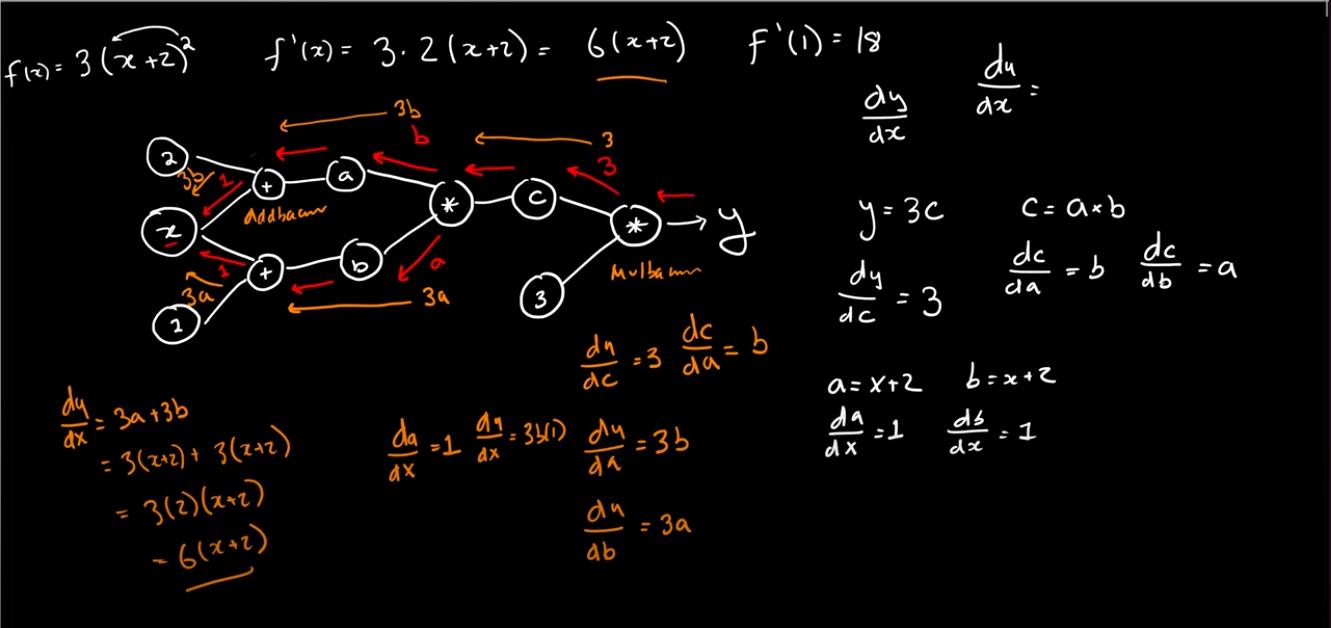

In [6]:
# sample fuction : f(x) = 3*(x + 2)**2
#

In [7]:
x = torch.ones(1,requires_grad = True)
y = x+2
z = y**2 * 3

# #How do we compute the derivative --> we need to enable grad by adding "requires_grad = true"
z.backward()
x.grad

tensor([18.])

**Linear Regression**

## 📘 Linear Regression Overview

In **Linear Regression**, we aim to model the relationship between:

- **X**: Independent variable(s) (input features)  
- **y**: Dependent variable (target output)

---

### 🔹 1. Data Representation

$$
(X, y)
$$

Where `X` is the input and `y` is the output.

---

### 🔹 2. Linear Model Equation

$$
y = mx + b
$$

- `m` is the slope (or weight)  
- `b` is the intercept (or bias)

---

### 🔹 3. Loss Function: Mean Squared Error (MSE)

$$
\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (y_i - \hat{y}_i)^2
$$

- \( y_i \): Actual value  
- \(\hat{y}_i \): Predicted value  
- \( N \): Number of data points

---

💡 **Goal**: Minimize the MSE by adjusting `m` and `b` to make the predicted values \( \hat{y} \) as close as possible to the actual `y`.


finding inverse is defficult using larger dataset.

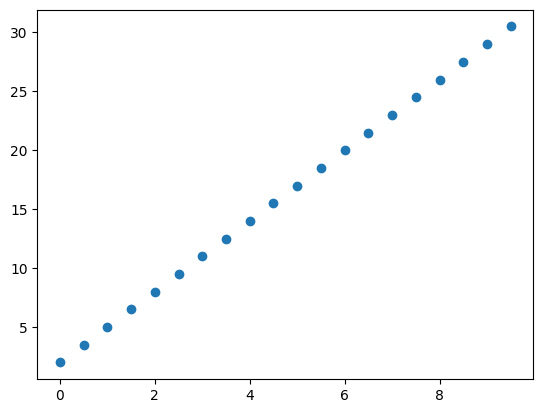

In [8]:
X = np.arange(0,10,0.5)
y = 2+3*X

plt.scatter(X,y)
plt.show()

In [9]:
X,y = X.reshape(-1,1) , y.reshape(-1,1)

model = LinearRegression()
model.fit(X,y)

model.coef_ , model.intercept_

(array([[3.]]), array([2.]))

### **How About PyTorch?**

We will use **gradient descent** to optimize our model parameters.

---

#### **Steps of Gradient Descent:**

1. **Start at a random position**  
   Initialize the weights randomly.

2. **Calculate the derivative (gradient):**  
   This tells us how the loss changes with respect to each parameter.

   - Is the derivative **positive or negative**?
   - The gradient points in the direction of **increase** — but we want to **minimize** the loss.
   - So, we take a small step in the **opposite direction** of the gradient.


Learning rate

In [10]:

class SGDRegressor(nn.Module):#inherit
  def __init__(self): # pieces of the module
    super().__init__()
    self.fcl = nn.Linear(1,1) #takes one input and gives one output

  def forward(self , x):# data(x) to module
    y = self.fcl(x)
    return y

model = SGDRegressor()
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters() , lr = 0.01)

EPOCHS = 5000
# list(model.parameters())

X_train = torch.tensor(X , dtype = torch.float32)
y_train = torch.tensor(y, dtype = torch.float32)



In [11]:
for epoch in range(EPOCHS):

  y_pred = model.forward(X_train)
  loss = loss_fn(y_pred, y_train)
  #print(loss)
  loss.backward()
  optimizer.step()
  # we need to reinitialize the gradient so it does not accuulate
  optimizer.zero_grad()
  #print(model.fcl.weight.grad)


In [12]:
for name,param in model.named_parameters():
  print(name , param)

fcl.weight Parameter containing:
tensor([[3.0000]], requires_grad=True)
fcl.bias Parameter containing:
tensor([2.0000], requires_grad=True)


In [13]:
X.shape # n x 1

(20, 1)

**Logistic Regression**

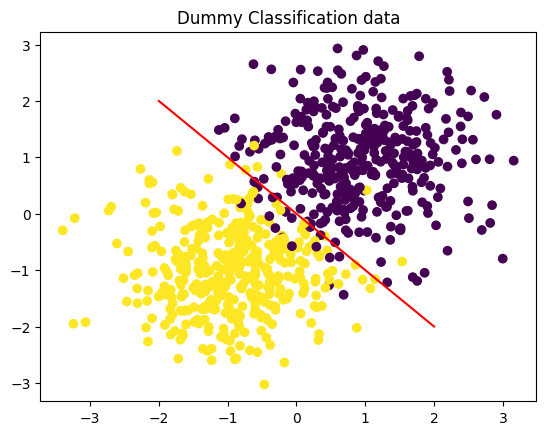

In [14]:
centers = [[1,1,] , [-1,-1]]

X,y = make_blobs(n_samples = 750 , centers = centers , cluster_std= 0.8 , random_state = 0)

plt.scatter(X[:,0] , X[:,1] , c = y )
plt.title("Dummy Classification data")
plt.plot([-2,2] , [2,-2] , "r")
plt.show()

y = y.reshape(-1,1)

In [15]:
y

array([[0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [1],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
    

In [16]:
X

array([[ 0.68044078,  1.29604471],
       [ 0.69050332,  0.59176581],
       [ 0.35727227,  0.44836018],
       ...,
       [-2.46402284, -1.5566681 ],
       [ 1.22742374,  2.39413502],
       [-1.79907904, -1.59210943]])

In [17]:
torch.manual_seed(42)

class LogisticRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.fcl = nn.Linear(2, 1)
    
    def forward(self, x):
        z = self.fcl(x)
        y = torch.sigmoid(z)
        return y

model = LogisticRegression()
loss_fn = torch.nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
EPOCHS = 5000

# Assuming X and y are your numpy arrays or lists
x_train = torch.tensor(X, dtype=torch.float32)
y_train = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)  # BCELoss expects same shape

In [18]:
module(x_train).shape

NameError: name 'module' is not defined

In [ ]:
x_train.shape

torch.Size([750, 2])

In [ ]:
y_train.shape

torch.Size([750, 1])

In [ ]:
for epoch in range(EPOCHS):
  y_pred = model(x_train)
  loss = loss_fn(y_pred,y_train)
  loss.backward()
  optimizer.step()
  optimizer.zero_grad()

In [ ]:
with torch.inference_mode():
  y_final_pred = model(x_train)

torch.mean(((y_final_pred > 0.5).int() ==y_train).float())

tensor(0.9680)

# Dense MNIST Deep learning

In [ ]:
### LOAD DATA ###
train = torchvision.datasets.MNIST('../../data', train=True, download=True,
                      transform=transforms.Compose([ ### CONVERT ARRAY TO TENSOR
                          transforms.ToTensor()
                       ]))

test = torchvision.datasets.MNIST('../../data', train=False, download=True,
                       transform=transforms.Compose([
                           transforms.ToTensor()
                       ]))


print(train)

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9.91M/9.91M [00:32<00:00, 302kB/s] 


Extracting ../../data\MNIST\raw\train-images-idx3-ubyte.gz to ../../data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28.9k/28.9k [00:00<00:00, 220kB/s]


Extracting ../../data\MNIST\raw\train-labels-idx1-ubyte.gz to ../../data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1.65M/1.65M [00:03<00:00, 490kB/s]


Extracting ../../data\MNIST\raw\t10k-images-idx3-ubyte.gz to ../../data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]

Extracting ../../data\MNIST\raw\t10k-labels-idx1-ubyte.gz to ../../data\MNIST\raw

Dataset MNIST
    Number of datapoints: 60000
    Root location: ../../data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
           )


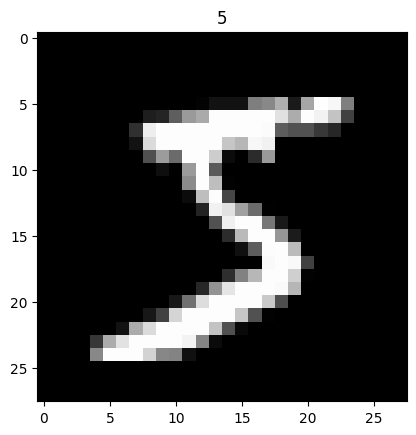

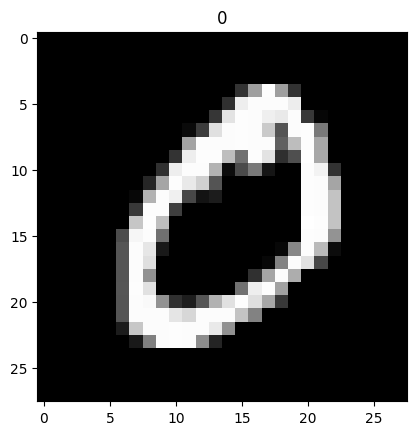

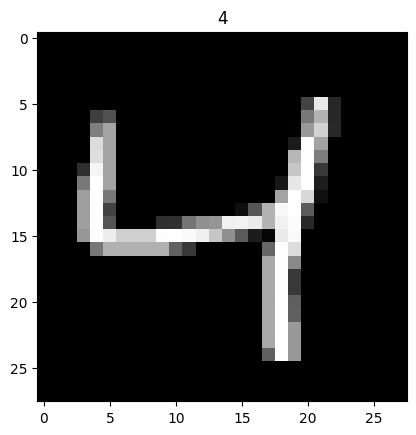

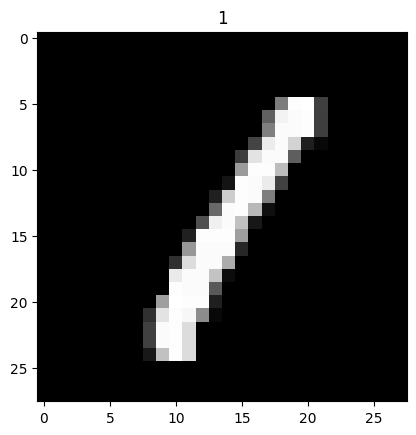

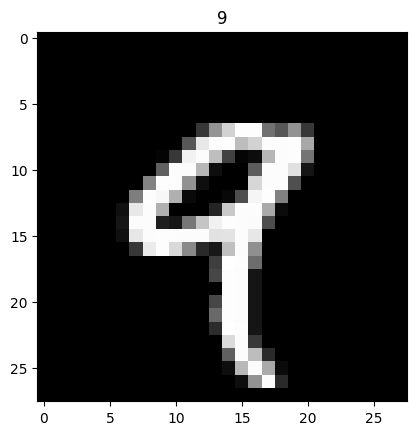

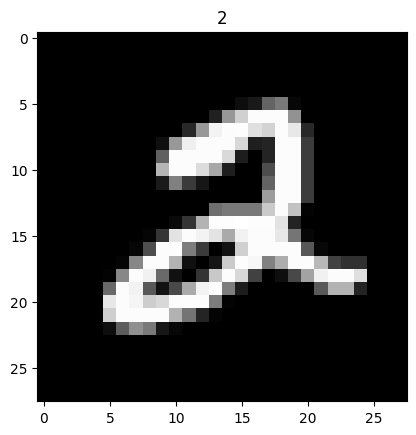

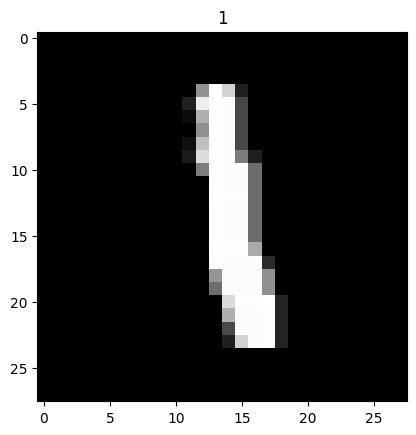

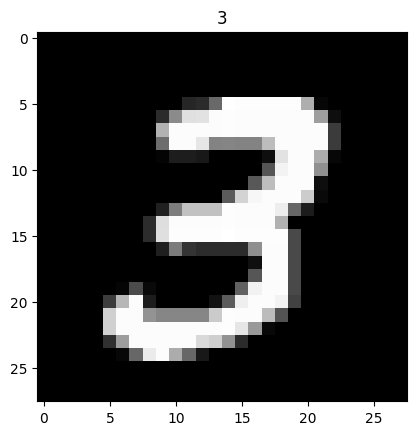

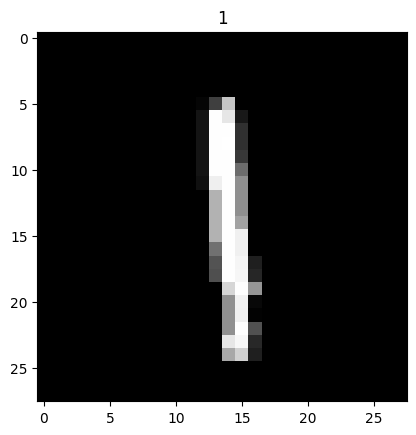

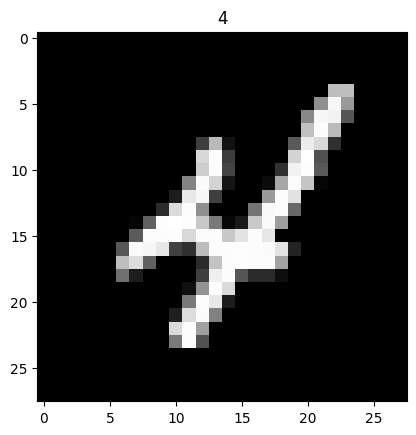

In [ ]:
counter = 0
for image,label in train:
  image = image.squeeze() #squeeze removed redundant dimensions
  plt.imshow(image , cmap = "grey")
  #print(image.shape)
  plt.title(label)
  plt.show()
  counter +=1
  if counter == 10 :
    break

# **Neural Network Considerations**

### 🔁 Batch Size and Epochs

- **Batch Size**: The number of samples processed before the model updates.
- **Example**:  
  Let total samples \( N = 2000 \), and batch size = 200  
  Then,  
$\text{Number of batches} = \frac{N}{\text{batch size}} = \frac{2000}{200} = 10$


- **Epoch**: One full pass through the entire dataset.  
  In this case, 10 batches make up one epoch.

---

### ⚙️ Optimizers

- **Stochastic Gradient Descent (SGD)**:  
  Makes updates using small, random subsets (batches) of data.  
  It **assumes no local minimum**, helping to escape shallow traps.

- **Adam Optimizer**:  
  A more advanced optimizer that adjusts the learning rate for each parameter.  
  Often performs better in practice — but still, **trial and error** is key!

---

### ❌ Loss Functions

- Measure how far off our model’s predictions are from the true values.  
- The goal of training is to minimize this loss.

---

### 🚀 Learning Rate

- Controls **how big the steps** are during optimization.
- Too high → may overshoot the minimum  
- Too low → may converge too slowly or get stuck


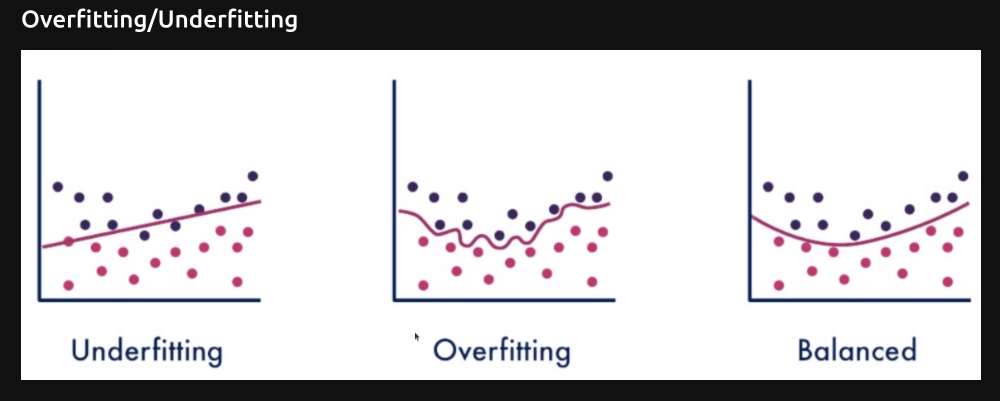

### 🎯 Model Fit and Generalization

- **Overfitting** → The model **memorizes** the training data and performs poorly on unseen data.
- **Underfitting** → The model **hasn't learned enough**, often due to being too simple or not trained long enough.

The ultimate goal is **generalization** — performing well on both training and new, unseen data.

---

### 🔍 How Can We Overfit?

- Training for **too many epochs**
- Using a model that is **too complex** for the amount of data (too many layers or parameters)

> ⚠️ Overfitting means the model has become excellent at training data, but terrible at real-world predictions.


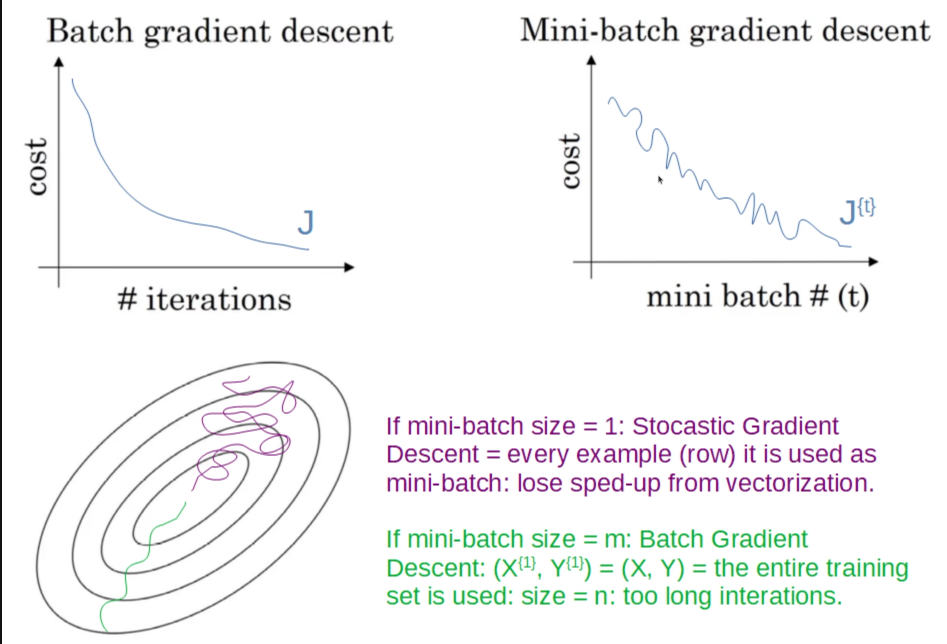

NN --> Is basically a stack of linear and non linear fuctions. the more we have the "Deeper"

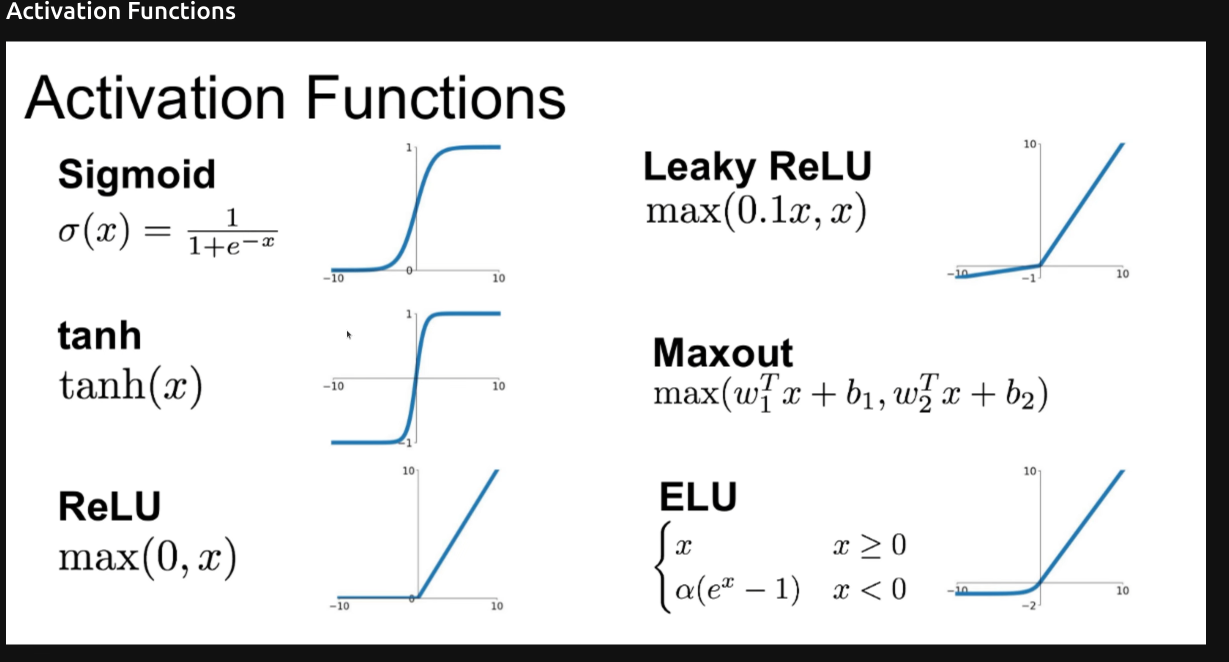

In [ ]:
BATCH_SIZE = 128
LOSS = nn.CrossEntropyLoss()
LR = 0.001
EPOCH = 5

In [ ]:
# Dataloader --> Logic that wraps the data and gets the batchs

trainset = torch.utils.data.DataLoader(train , batch_size = BATCH_SIZE , shuffle = True)

testset = torch.utils.data.DataLoader(train , batch_size = BATCH_SIZE , shuffle = True)

for images,labels in trainset:
  print(images.shape)
  print(labels)
  break

torch.Size([128, 1, 28, 28])
tensor([9, 3, 7, 7, 4, 2, 8, 8, 0, 4, 8, 3, 6, 4, 5, 4, 0, 7, 8, 4, 3, 2, 7, 6,
        6, 0, 4, 4, 2, 6, 6, 8, 2, 3, 5, 7, 3, 8, 0, 6, 8, 3, 6, 6, 9, 9, 2, 5,
        5, 8, 0, 5, 4, 0, 7, 8, 9, 0, 9, 4, 0, 2, 5, 3, 3, 0, 6, 5, 9, 3, 8, 0,
        0, 0, 5, 9, 6, 8, 3, 1, 7, 0, 9, 2, 6, 8, 5, 6, 2, 2, 3, 6, 0, 8, 6, 0,
        4, 1, 7, 4, 9, 7, 9, 8, 2, 7, 6, 6, 2, 1, 3, 7, 3, 5, 4, 5, 5, 8, 1, 3,
        7, 7, 6, 0, 9, 3, 6, 4])


# Components of a NN Archetecture

# 🧠 Neural Network Core Components

---

## 🔧 `__init__`: Network Architecture Definition

The `__init__` method sets up the layers of your neural network. You define:
- An input layer of size `input_size`
- A hidden layer of size `hidden_size`
- An output layer of size `output_size`

This means two linear transformations:
1. Input → Hidden
2. Hidden → Output

### 📐 Mathematical View

Let:
- $x \in \mathbb{R}^{\text{input\_size}}$
- $W_1 \in \mathbb{R}^{\text{hidden\_size} \times \text{input\_size}},\quad b_1 \in \mathbb{R}^{\text{hidden\_size}}$
- $W_2 \in \mathbb{R}^{\text{output\_size} \times \text{hidden\_size}},\quad b_2 \in \mathbb{R}^{\text{output\_size}}$

---

## 🚀 `forward`: Data Flow Through the Network

The `forward` method defines how the input moves through the network:

### 🔬 Computation Steps

1. Apply the first linear transformation:
   $$
   z_1 = W_1 x + b_1
   $$

2. Apply the ReLU activation:
   $$
   h = \text{ReLU}(z_1) = \max(0, z_1)
   $$

3. Apply the second linear transformation:
   $$
   \hat{y} = W_2 h + b_2
   $$

---

## 📊 `softmax`: Turning Scores Into Probabilities

The `softmax` function converts the output logits into a probability distribution.

### 📘 Softmax Formula

For each class score $z_i$:

$$
\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}
$$

Where:
- $z_i$ is the logit for class $i$
- $K$ is the number of classes
- Output values lie in $[0,1]$ and sum to 1.

Example:  
Given logits $[2.0,\ 1.0,\ 0.1]$, softmax returns approximately $[0.659,\ 0.242,\ 0.099]$.

---

## ✅ Summary Table

| Component   | Purpose                                                  |
|-------------|----------------------------------------------------------|
| `__init__`  | Initializes the network structure and layers             |
| `forward`   | Defines the step-by-step data computation                |
| `softmax`   | Converts output scores to class probabilities            |

These three components form the basic skeleton of most neural networks used in classification tasks.


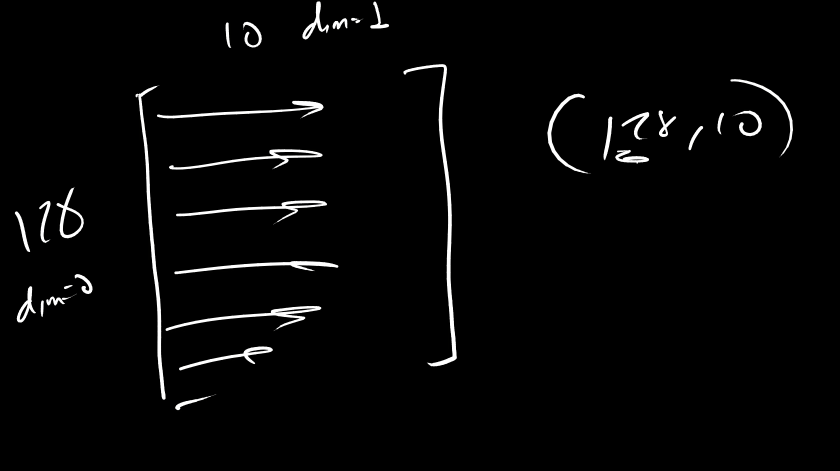

In [ ]:
class FCNet(nn.Module):
  def __init__(self):

    super().__init__()
    self.fc1 = nn.Linear(28*28 , 64)
    self.fc2 = nn.Linear(64 , 128)
    self.fc3 = nn.Linear(128 , 64)
    self.fc4 = nn.Linear(64 , 10)

  def forward(self , x):
    batch_size = x.shape[0]
    x = x.reshape(batch_size , -1)
    # x = x.flatten(1) #starts from first dimension

    x = F.relu(self.fc1(x)) #activation fuctions should not be here, last layers should be left as projections,
    x = F.relu(self.fc2(x))
    x = F.relu(self.fc3(x))
    x = self.fc4(x)
    # print(logits.shape)
    # print(x.shape)
    # x = F.log_softmax(x , dim = 1) happens intenally
    return x
    pass

#BCE Loss : expects 1 output where 0.5 > 1 and
# CE Loss

In [ ]:
rand = torch.randn(128 , 1,28,28)
model = FCNet()
model(rand)
# print(a.flatten()) #flattens to a single vector

tensor([[ 0.0529,  0.0043, -0.0443,  ..., -0.0614,  0.0080,  0.0639],
        [ 0.0902,  0.0530, -0.0723,  ..., -0.0736, -0.0022,  0.0376],
        [ 0.0608,  0.0384, -0.0010,  ..., -0.0738, -0.0186,  0.0444],
        ...,
        [ 0.0330,  0.0235, -0.0135,  ..., -0.0612,  0.0062,  0.0241],
        [ 0.0257,  0.0031, -0.0176,  ..., -0.0965,  0.0021,  0.0136],
        [ 0.0840,  0.0403, -0.0036,  ..., -0.0813, -0.0122,  0.0670]],
       grad_fn=<AddmmBackward0>)

In [ ]:
model = FCNet()
optimizer = optim.Adam(model.parameters() , lr = LR)

for epoch in range(EPOCH):

  print(f"Training Epoch {epoch+1}")
  losses = []
  for images,labels in trainset:
      # print(images.shape)
      # print(labels)

      forward_out = model(images)
      loss = LOSS(forward_out , labels)
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
      # print(loss.item())
      losses.append(loss.item())

  print(f"Loss: {np.mean(losses)}")

Training Epoch 1
Loss: 0.46321743005501437
Training Epoch 2
Loss: 0.18122665042371383
Training Epoch 3
Loss: 0.13066587252800527
Training Epoch 4
Loss: 0.10429361851206784
Training Epoch 5
Loss: 0.08568661053106984


In [ ]:
correct = 0
total = 0

model.eval()
with torch.inference_mode():
  for images,labels in testset:
    forward_out = model(images)
    for idx, i in enumerate(forward_out):
      prediction = torch.argmax(i)
      if prediction == labels[idx]:
        correct +=1
      total +=1

print(f"Accuracy = {round(correct/total , 2)}")

Accuracy = 0.98


# **GPU Incoperation**

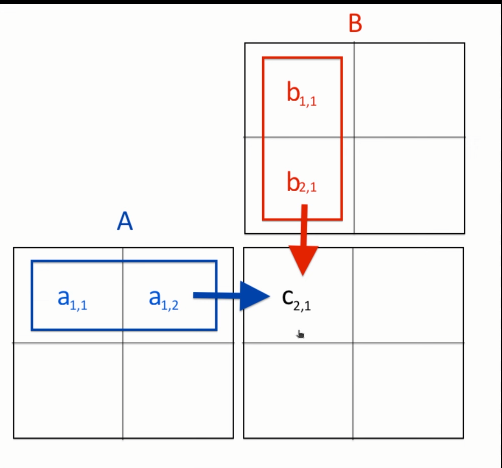

Matrix multiplication is very parallizaabl. Cuda lets us do the amtrix multiplication in different parallelization.

In [19]:
import torch

try:
    cuda_available = torch.cuda.is_available()
    print(f"CUDA available: {cuda_available}")
except Exception as e:
    print(f"Error checking CUDA: {e}")

CUDA available: False


In [ ]:
# # we set the decice
# DEVICE = "cuda:0"

# model = FCNet().to(Device)
# model

NameError: name 'FCNet' is not defined

In [ ]:
!nvidea-smi

'nvidea-smi' is not recognized as an internal or external command,
operable program or batch file.
